In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import dtale as dt
import sklearn as sk

In [6]:
df = pd.read_csv("diabetes.csv")
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,6,148,72,35,0,33.6,0.627,50,1
2,1,85,66,29,0,26.6,0.351,31,0
3,8,183,64,0,0,23.3,0.672,32,1
4,1,89,66,23,94,28.1,0.167,21,0
...,...,...,...,...,...,...,...,...,...
764,10,101,76,48,180,32.9,0.171,63,0
765,2,122,70,27,0,36.8,0.340,27,0
766,5,121,72,23,112,26.2,0.245,30,0
767,1,126,60,0,0,30.1,0.349,47,1


In [7]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,6,148,72,35,0,33.6,0.627,50,1
2,1,85,66,29,0,26.6,0.351,31,0
3,8,183,64,0,0,23.3,0.672,32,1
4,1,89,66,23,94,28.1,0.167,21,0


In [8]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
764,10,101,76,48,180,32.9,0.171,63,0
765,2,122,70,27,0,36.8,0.340,27,0
766,5,121,72,23,112,26.2,0.245,30,0
767,1,126,60,0,0,30.1,0.349,47,1
768,1,93,70,31,0,30.4,0.315,23,0


In [9]:
df.shape

(769, 9)

In [10]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

In [11]:
df.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 769 entries, 0 to 768
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               769 non-null    int64  
 1   Glucose                   769 non-null    int64  
 2   BloodPressure             769 non-null    int64  
 3   SkinThickness             769 non-null    int64  
 4   Insulin                   769 non-null    int64  
 5   BMI                       769 non-null    float64
 6   DiabetesPedigreeFunction  769 non-null    float64
 7   Age                       769 non-null    int64  
 8   Outcome                   769 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.2 KB


In [13]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(1)

In [15]:
df[df.duplicated()]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
1,6,148,72,35,0,33.6,0.627,50,1


In [16]:
df = df.drop_duplicates()

In [17]:
(df == 0).sum()

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

In [18]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


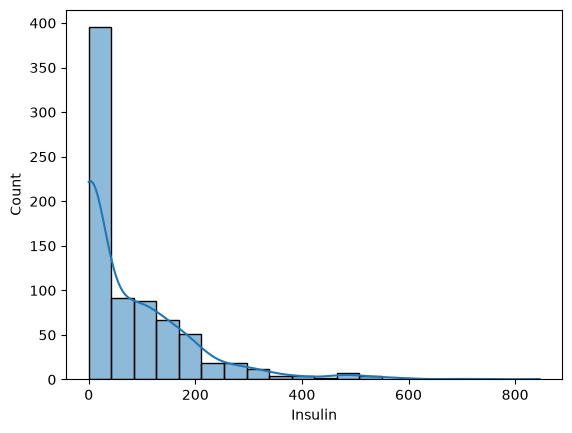

In [19]:
sns.histplot(df['Insulin'], bins=20, kde=True)
plt.show()

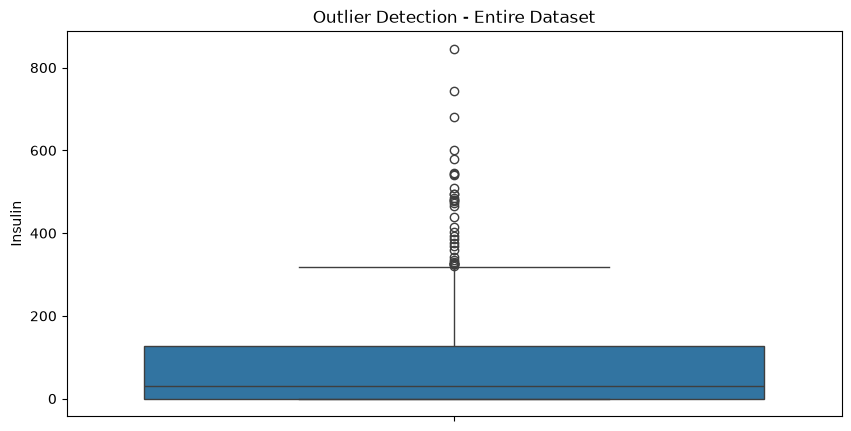

In [20]:
plt.figure(figsize=(10, 5))

# sns.boxplot(data=df.select_dtypes(include='number'))
sns.boxplot(data = df["Insulin"])

plt.xticks(rotation=45)
plt.title("Outlier Detection - Entire Dataset")
plt.show()

In [21]:
# Interquartile Range (IQR) method for outlier detection
Q1 = df['Insulin'].quantile(0.25)
Q3 = df['Insulin'].quantile(0.75)
IQR = Q3 - Q1

print("IQR:", IQR)

# if the number of outliers is less then  min =  Q1 - 1.5 * IQR then it is considered as outlier
# if the number of outliers is more then  max =  Q3 + 1.5 * IQR then it is considered as outlier

IQR: 127.25


In [22]:
df.min()

Pregnancies                  0.000
Glucose                      0.000
BloodPressure                0.000
SkinThickness                0.000
Insulin                      0.000
BMI                          0.000
DiabetesPedigreeFunction     0.078
Age                         21.000
Outcome                      0.000
dtype: float64

In [23]:
columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

df[columns] = np.where(df[columns] == 0, df[columns].median(), df[columns])

In [24]:
df.min()

Pregnancies                  0.000
Glucose                     44.000
BloodPressure               24.000
SkinThickness                7.000
Insulin                     14.000
BMI                         18.200
DiabetesPedigreeFunction     0.078
Age                         21.000
Outcome                      0.000
dtype: float64

In [25]:
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,30.5,33.6,0.627,50,1
2,1,85.0,66.0,29.0,30.5,26.6,0.351,31,0
3,8,183.0,64.0,23.0,30.5,23.3,0.672,32,1
4,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
5,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
764,10,101.0,76.0,48.0,180.0,32.9,0.171,63,0
765,2,122.0,70.0,27.0,30.5,36.8,0.340,27,0
766,5,121.0,72.0,23.0,112.0,26.2,0.245,30,0
767,1,126.0,60.0,23.0,30.5,30.1,0.349,47,1


In [26]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [27]:
df.info()

<class 'pandas.DataFrame'>
Index: 768 entries, 0 to 768
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    float64
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    float64
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(6), int64(3)
memory usage: 60.0 KB


In [28]:
from sklearn.model_selection import train_test_split

x = df.iloc[:,:-1]
y = df.iloc[:,-1]
    

In [29]:
# x = df.drop(columns="Outcome")
# y = df["Outcome"]

# X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)


# print("X_train shape:", X_train.shape)
# print("X_test shape:", X_test.shape)


In [30]:
# x.value_counts(normalize=True)
y.value_counts(normalize=True)

Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64

In [31]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.3, random_state = 42, stratify = y)

In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score

c:\Users\anirudh.sharma\Desktop\New folder\DiabetesPrediction_ML_Model\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\anirudh.sharma\Desktop\New folder\DiabetesPrediction_ML_Model\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to s

                            Model  Accuracy  Precision
0             Logistic Regression  0.748918   0.682540
1        Decision Tree Classifier  0.675325   0.542857
2        Random Forest Classifier  0.757576   0.692308
3    Gradient Boosting Classifier  0.748918   0.676923
4       Support Vector Classifier  0.740260   0.705882
5  K-Nearest Neighbors Classifier  0.701299   0.588235
6              XGBoost Classifier  0.735931   0.642857
7               Voting Classifier  0.735931   0.666667


<Axes: xlabel='Accuracy', ylabel='Model'>

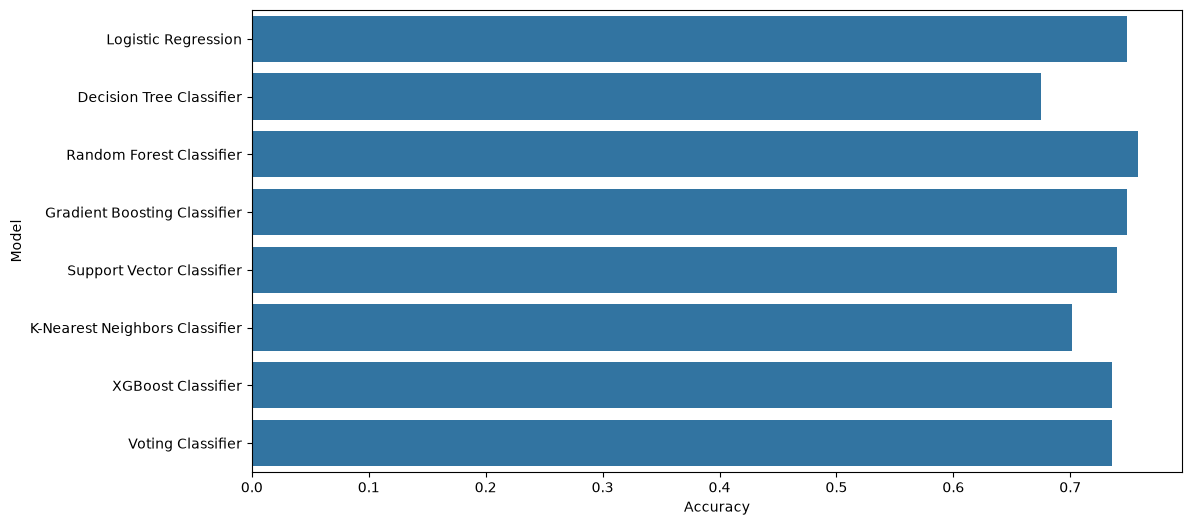

In [ ]:
# logistic regression

logistic_model = LogisticRegression(random_state=42)
logistic_model.fit(x_train, y_train)
logistic_predictions = logistic_model.predict(x_test)
logistic_accuracy = accuracy_score(y_test, logistic_predictions)
logistic_precision = precision_score(y_test, logistic_predictions)


# Decision Tree Classifier
dictree_model = DecisionTreeClassifier(random_state=42)
dictree_model.fit(x_train, y_train)
tree_predictions = dictree_model.predict(x_test)
dictree_accuracy = accuracy_score(y_test, tree_predictions)
dictree_precision = precision_score(y_test, tree_predictions)


# Random Forest Classifier

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(x_train, y_train)
rf_predictions = rf_model.predict(x_test)
rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(y_test, rf_predictions)


#  gradient Boosting Classifier
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(x_train, y_train)
gb_predictions = gb_model.predict(x_test)
gb_accuracy = accuracy_score(y_test, gb_predictions)
gb_precision = precision_score(y_test, gb_predictions)

#  Support Vector Classifier
svc_model = SVC(random_state=42)
svc_model.fit(x_train, y_train)
svc_predictions = svc_model.predict(x_test)
svc_accuracy = accuracy_score(y_test, svc_predictions)
svc_precision = precision_score(y_test, svc_predictions)

# K-Nearest Neighbors Classifier
KNN_model = KNeighborsClassifier()
KNN_model.fit(x_train, y_train)
KNN_predictions = KNN_model.predict(x_test)
KNN_accuracy = accuracy_score(y_test, KNN_predictions)
KNN_precision = precision_score(y_test, KNN_predictions)


# XGBoost Classifier
xgb_model = XGBClassifier(random_state=42)
xgb_model.fit(x_train, y_train)
xgb_predictions = xgb_model.predict(x_test)
xgb_accuracy = accuracy_score(y_test, xgb_predictions)
xgb_precision = precision_score(y_test, xgb_predictions)



voting_model = VotingClassifier(estimators=[('logistic', logistic_model),('decision_tree', dictree_model),('random_forest', rf_model),('gradient_boosting', gb_model),
                                            ('svc', svc_model),('knn', KNN_model),('xgb', xgb_model)], voting='hard')
voting_model.fit(x_train, y_train)
voting_predictions = voting_model.predict(x_test)
voting_accuracy = accuracy_score(y_test, voting_predictions)
voting_precision = precision_score(y_test, voting_predictions)


list_of_models = [
    ('Logistic Regression', logistic_model, logistic_accuracy, logistic_precision),
    ('Decision Tree Classifier', dictree_model, dictree_accuracy, dictree_precision),
    ('Random Forest Classifier', rf_model, rf_accuracy, rf_precision),
    ('Gradient Boosting Classifier', gb_model, gb_accuracy, gb_precision),
    ('Support Vector Classifier', svc_model, svc_accuracy, svc_precision),
    ('K-Nearest Neighbors Classifier', KNN_model, KNN_accuracy, KNN_precision),
    ('XGBoost Classifier', xgb_model, xgb_accuracy, xgb_precision),
    ('Voting Classifier', voting_model, voting_accuracy, voting_precision)
]

list1 = [accuracy for _, _, accuracy, _ in list_of_models]
list2 = [precision for _, _, _, precision in list_of_models]
list3 = [model for model, _, _, _ in list_of_models]


df_results = pd.DataFrame({
    'Model': list3,
    'Accuracy': list1,
    'Precision': list2
})

print(df_results)

plt.figure(figsize=(12, 6))
sns.barplot(x='Accuracy', y='Model', data=df_results)
